# 06 · La conception des Pokémon au fil des générations

Deux questions dans ce notebook :
1. **Est-ce que les Pokémon ont changé de conception au fil des générations ?** Plus forts, plus gros, plus colorés ?
2. **Les générations récentes sont moins aimées : est-ce à cause du design, ou de la nostalgie ?** Si c'est le design, la popularité devrait dépendre des attributs de conception même à génération égale.

Méthode principale : la **PCA** (TP4) sur les attributs de conception, puis la trajectoire des générations dans le plan factoriel. Pour la popularité, on garde comme d'habitude chaque source à part (Reddit, Johto Times, Google Trends), en percentile.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
couleurs = pd.read_csv(OUT / "couleurs_sprites.csv", index_col="dex")
pop = pd.read_csv(OUT / "popularite_sources.csv", index_col="dex")
print(table.shape, couleurs.shape, pop.shape)
couleurs.head()

(1025, 35) (1025, 13) (1025, 19)


,nb_couleurs,dom_r,dom_v,dom_b,dom_hex,dom_teinte,dom_saturation,dom_luminosite,dom_part,saturation_moyenne,luminosite_moyenne,palette,famille_dominante
dex,,,,,,,,,,,,,
1,1,125,173,145,#7dad91,145.1,0.281,0.680,0.941,0.286,0.691,#7dad91:0.941;#f2f3f8:0.030;#a95c69:0.028,green
2,3,119,167,154,#77a79a,163.0,0.287,0.655,0.560,0.369,0.669,#77a79a:0.560;#4c8898:0.296;#d18490:0.145,green
3,3,93,144,134,#5d9086,167.7,0.353,0.565,0.551,0.378,0.564,#5d9086:0.551;#333431:0.214;#cf7479:0.186;#e2c...,green
4,2,213,159,118,#d59f76,25.5,0.446,0.836,0.650,0.380,0.839,#d59f76:0.650;#eadac5:0.266;#66453c:0.041;#e17...,brown
5,2,204,108,91,#cc6c5b,8.9,0.553,0.802,0.691,0.460,0.808,#cc6c5b:0.691;#d9c1b3:0.213;#f8cf6c:0.037;#553...,red


In [2]:
couleurs.describe().T

,count,mean,std,min,25%,50%,75%,max
nb_couleurs,1025.0,3.090732,1.114781,1.000,2.000,3.000,4.000,7.000
dom_r,1025.0,157.470244,63.763443,2.000,102.000,165.000,216.000,254.000
dom_v,1025.0,150.644878,58.283258,7.000,100.000,155.000,202.000,254.000
dom_b,1025.0,141.841951,58.062991,8.000,94.000,139.000,192.000,254.000
dom_teinte,1025.0,146.804000,112.347493,0.500,37.400,146.500,229.500,359.200
dom_saturation,1025.0,0.285455,0.207982,0.000,0.106,0.253,0.440,0.990
dom_luminosite,1025.0,0.689440,0.221351,0.030,0.544,0.752,0.871,0.996
dom_part,1025.0,0.589308,0.177994,0.192,0.461,0.563,0.704,1.000
saturation_moyenne,1025.0,0.302264,0.140974,0.014,0.195,0.298,0.404,0.800
luminosite_moyenne,1025.0,0.690580,0.137887,0.227,0.597,0.700,0.799,0.961


Le notebook 03 donne pour chaque Pokémon le nombre de couleurs importantes (de 1 à 7, médiane 3, sans compter le contour noir du dessin), la couleur dominante (RGB, teinte, saturation, luminosité, part du corps qu'elle couvre, 59 % en moyenne) et la saturation et la luminosité moyennes de tout le corps.

## 1. Les attributs de conception par génération

On assemble les attributs « de conception » : les 6 stats de combat, la taille et le poids, et les variables de couleur calculées sur les images (notebook 03). La taille et le poids sont très asymétriques (quelques Pokémon énormes, comme Éthernatos à 20 m), du coup **on les passe en log** : sinon ces quelques géants écraseraient tout le reste dans les moyennes et dans la PCA.

In [3]:
df = table.join(couleurs[["nb_couleurs", "saturation_moyenne", "luminosite_moyenne", "dom_part"]]).join(
    pop[["reddit_pct", "reddit_pct_gen", "johto_pct_gen", "trends_pct_median", "trends_pct_gen"]])
df["log_taille"] = np.log10(df["taille_m"])
df["log_poids"] = np.log10(df["poids_kg"])
attributs = ["total_stats", "log_taille", "log_poids", "nb_couleurs", "saturation_moyenne", "luminosite_moyenne"]
df[attributs].isna().sum()

total_stats           0
log_taille            0
log_poids             0
nb_couleurs           0
saturation_moyenne    0
luminosite_moyenne    0
dtype: int64

In [4]:
df.groupby("generation")[attributs + ["taille_m", "poids_kg"]].median().round(2)

,total_stats,log_taille,log_poids,nb_couleurs,saturation_moyenne,luminosite_moyenne,taille_m,poids_kg
generation,,,,,,,,
1,405.0,0.00,1.48,3.0,0.28,0.76,1.0,30.00
2,415.0,-0.05,1.43,3.0,0.33,0.75,0.9,26.75
3,410.0,0.00,1.45,3.0,0.27,0.77,1.0,28.40
4,480.0,0.00,1.48,3.0,0.32,0.66,1.0,29.90
5,445.5,0.00,1.45,3.0,0.26,0.65,1.0,28.40
6,450.0,-0.10,1.20,3.0,0.31,0.70,0.8,15.75
7,480.0,-0.05,1.34,3.0,0.27,0.68,0.9,21.80
8,481.5,0.04,1.46,3.0,0.32,0.65,1.1,29.00
9,488.5,0.08,1.54,3.0,0.37,0.67,1.2,35.00


En médiane, le total des stats passe d'environ 405-415 (générations 1 à 3) à 480-490 (générations 7 à 9). Le nombre de couleurs médian est de 3 dans toutes les générations (la moyenne, elle, monte : de 2,6 en génération 1 à 3,6-3,7 en générations 7 et 9, voir le notebook 03). La taille et le poids médians ne bougent presque pas (environ 1 m et 30 kg), sauf un creux en génération 6 (0,8 m, 16 kg).

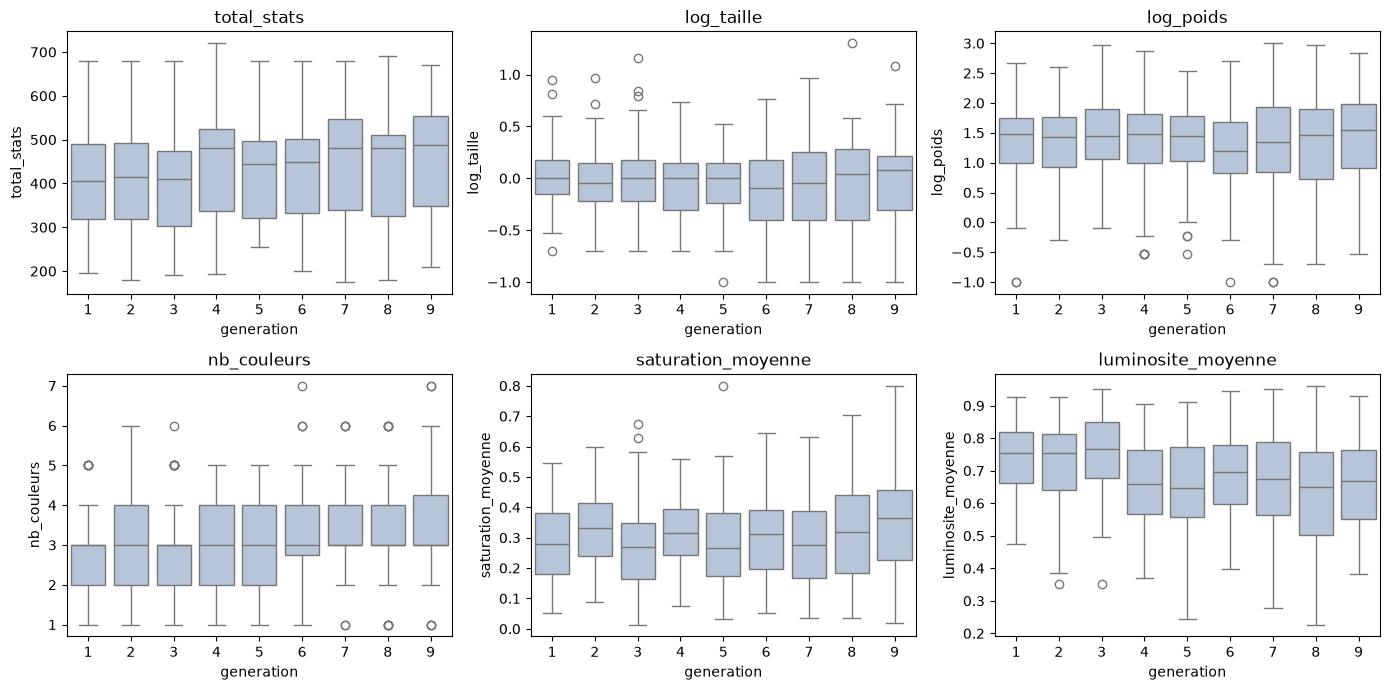

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, a in zip(axes.flat, attributs):
    sns.boxplot(data=df, x="generation", y=a, ax=ax, color="lightsteelblue")
    ax.set_title(a)
plt.tight_layout()
plt.show()

Pour savoir si les différences entre générations sont réelles, on fait deux tests :
- **Kruskal-Wallis** : est-ce que les 9 générations ont la même distribution ? (version non paramétrique de l'ANOVA, pas besoin de normalité) ;
- **Spearman avec le numéro de génération** : est-ce qu'il y a une **tendance** (ça monte ou ça descend au fil du temps) ?

In [6]:
lignes = []
for a in attributs:
    groupes = [d[a].dropna() for _, d in df.groupby("generation")]
    kw = stats.kruskal(*groupes)
    sp = stats.spearmanr(df["generation"], df[a])
    lignes.append({"attribut": a, "kruskal_H": kw.statistic, "kruskal_p": kw.pvalue, "spearman_rho": sp.statistic, "spearman_p": sp.pvalue})
tests = pd.DataFrame(lignes).set_index("attribut")
tests.round(4)

,kruskal_H,kruskal_p,spearman_rho,spearman_p
attribut,,,,
total_stats,35.4597,0.0000,0.1574,0.0000
log_taille,7.9095,0.4424,-0.0001,0.9970
log_poids,7.2836,0.5064,0.0045,0.8864
nb_couleurs,101.6455,0.0000,0.2984,0.0000
saturation_moyenne,39.2640,0.0000,0.0830,0.0078
luminosite_moyenne,90.1056,0.0000,-0.2379,0.0000


- **les stats montent** au fil des générations (Spearman 0,16, p < 0,001) ;
- **le nombre de couleurs monte** encore plus nettement (0,30), et la **luminosité baisse** (-0,24) : les Pokémon récents sont plus colorés et un peu plus sombres ;
- la saturation varie entre générations (Kruskal-Wallis significatif) mais la tendance est très faible (0,08) ;
- **la taille et le poids ne changent pas** (p = 0,44 et 0,51) : les Pokémon ne sont pas devenus plus gros.

Les stats dépendent beaucoup du stade d'évolution et des légendaires, et la part de légendaires n'est pas la même dans chaque génération. Pour être sûrs que la hausse des stats n'est pas juste due à plus de légendaires, on refait la tendance **à stade égal**, en enlevant les légendaires et les fabuleux.

In [7]:
ordinaires = df[~df.legendaire & ~df.fabuleux]
print("part de légendaires + fabuleux par génération :")
print((df.legendaire | df.fabuleux).groupby(df.generation).mean().round(2).to_string())
lignes = []
for st, d in ordinaires.groupby("stade_categorie"):
    for a in ["total_stats", "log_poids", "nb_couleurs"]:
        sp = stats.spearmanr(d["generation"], d[a])
        lignes.append({"stade": st, "attribut": a, "n": len(d), "rho": sp.statistic, "p": sp.pvalue})
pd.DataFrame(lignes).pivot(index="stade", columns="attribut", values=["rho", "p"]).round(3)

part de légendaires + fabuleux par génération :
generation
1    0.03
2    0.06
3    0.07
4    0.13
5    0.08
6    0.08
7    0.18
8    0.12
9    0.10


rho                                 p              \
attribut       log_poids nb_couleurs total_stats log_poids nb_couleurs   
stade                                                                    
sans évolution     0.274       0.506       0.559     0.003       0.000   
stade 1           -0.217       0.219      -0.126     0.000       0.000   
stade 2           -0.065       0.287       0.154     0.218       0.000   
stade 3            0.050       0.280       0.210     0.590       0.002   

                            
attribut       total_stats  
stade                       
sans évolution       0.000  
stade 1              0.021  
stade 2              0.003  
stade 3              0.022

La part de légendaires et fabuleux passe de 3 % en génération 1 à 18 % en génération 7, ça pourrait gonfler les stats des générations récentes. Mais même **sans eux et à stade égal**, les stats montent avec la génération pour les stades 2 et 3 et pour les « sans évolution » (rho de 0,15 à 0,56). Les stades 1, eux, sont un peu **moins** forts et plus légers au fil des générations (rho -0,13 et -0,22). Le nombre de couleurs monte dans toutes les catégories de stade.

### Ce qu'on a fait et pourquoi

**1. Passer la taille et le poids en log.** Quelques Pokémon sont énormes (Éthernatos, Groudon…) et la plupart font autour d'un mètre. Sans le log, ces géants tireraient les moyennes et les écarts-types, et on ne verrait plus les différences entre Pokémon « normaux ». Le log ramène tout le monde sur une échelle où doubler de taille compte pareil, qu'on passe de 0,5 à 1 m ou de 10 à 20 m.

**2. Les médianes par génération, puis les boîtes à moustaches.** On a d'abord regardé les médianes plutôt que les moyennes, parce que ces variables ont des valeurs extrêmes (légendaires, géants). Ensuite, les boîtes à moustaches montrent toute la distribution de chaque génération d'un coup : la médiane, l'étalement et les cas extrêmes. Ça permet de voir tout de suite si une génération est vraiment décalée ou si c'est juste quelques Pokémon.

**3. Deux tests différents, parce qu'ils ne répondent pas à la même question.**
- **Kruskal-Wallis** répond à « est-ce que les générations sont différentes ? ». On l'a pris plutôt qu'une ANOVA parce qu'il ne demande pas que les données soient normales, et nos variables (stats, nombre de couleurs) ne le sont pas.
- **Spearman avec le numéro de génération** répond à « est-ce que ça monte ou descend au fil du temps ? ». Kruskal-Wallis peut être significatif sans qu'il y ait de tendance (une génération bizarre au milieu suffit), donc il fallait les deux. Spearman et pas Pearson, parce qu'on cherche une tendance qui monte, pas forcément une ligne droite.

**4. Refaire la tendance sans légendaires et à stade égal.** La part de légendaires n'est pas la même dans chaque génération, et un stade 3 est forcément plus fort qu'un stade 1. Si on ne contrôlait pas ça, « les stats montent » pourrait juste vouloir dire « il y a plus de légendaires récemment ». En coupant par stade et en enlevant les légendaires, on compare des Pokémon comparables.

## 2. La PCA des attributs de conception

Comme au TP4 : on **standardise** les variables (moyenne 0, écart-type 1), sinon le total des stats (des centaines) écraserait la saturation (entre 0 et 1). Puis on calcule les composantes principales.

Pour le choix des variables :
- on met **les 6 stats séparément** (et pas le total), pour que la PCA puisse voir les profils (rapide, défensif…). Le revers, c'est que les stats font la moitié des 12 variables, donc elles pèseront beaucoup sur le premier axe ;
- on ajoute la taille et le poids (en log) et 4 variables de couleur : nombre de couleurs, saturation, luminosité, part de la couleur dominante ;
- on **ne met pas la teinte** : c'est un angle (0° et 359° sont presque la même couleur), la PCA la traiterait comme deux valeurs opposées ;
- on **garde les légendaires et les fabuleux** : ils font partie du design des générations, les enlever reviendrait à cacher une partie de l'évolution. On regardera les tendances sans eux à côté, pour vérifier.

In [8]:
# les variables de la PCA (voir le choix juste au-dessus)
VARIABLES_PCA = ["pv", "attaque", "defense", "attaque_spe", "defense_spe", "vitesse",
                 "log_taille", "log_poids", "nb_couleurs", "saturation_moyenne", "luminosite_moyenne", "dom_part"]

X = StandardScaler().fit_transform(df[VARIABLES_PCA])
pca = PCA().fit(X)
variance = pd.DataFrame({"variance_expliquee": pca.explained_variance_ratio_,
                         "cumulee": pca.explained_variance_ratio_.cumsum(),
                         "valeur_propre": pca.explained_variance_},
                        index=[f"PC{i+1}" for i in range(len(VARIABLES_PCA))])
variance.round(3)

,variance_expliquee,cumulee,valeur_propre
PC1,0.334,0.334,4.008
PC2,0.161,0.494,1.928
PC3,0.107,0.601,1.282
PC4,0.085,0.686,1.020
PC5,0.074,0.760,0.885
PC6,0.057,0.817,0.685
PC7,0.050,0.866,0.598
PC8,0.042,0.908,0.503
PC9,0.035,0.943,0.419
PC10,0.023,0.966,0.272


Les 4 premières composantes ont une valeur propre au-dessus de 1 et gardent **69 %** de la variance (les deux premières en gardent 49 %). On décide de **garder ces 4 axes** (critère de Kaiser, comme au TP4) : une valeur propre au-dessus de 1 veut dire que l'axe résume plus d'information qu'une variable de départ toute seule, et la 5e composante tombe déjà à 0,88.

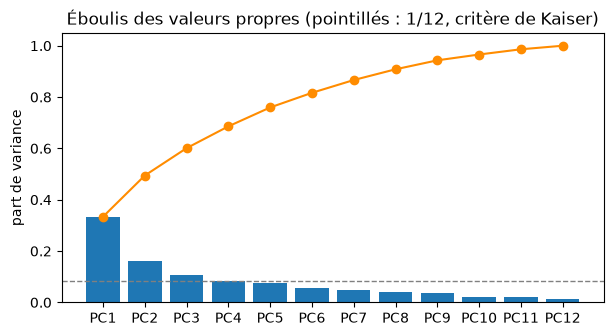

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(variance.index, variance.variance_expliquee)
ax.plot(variance.index, variance.cumulee, "o-", color="darkorange")
ax.axhline(1 / len(VARIABLES_PCA), ls="--", color="grey", lw=1)
ax.set_ylabel("part de variance")
ax.set_title("Éboulis des valeurs propres (pointillés : 1/12, critère de Kaiser)")
plt.show()

In [10]:
# les loadings : corrélation entre chaque variable et chaque composante
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=VARIABLES_PCA,
                        columns=variance.index).iloc[:, :4]
loadings.round(2)

,PC1,PC2,PC3,PC4
pv,0.69,-0.20,0.08,0.01
attaque,0.73,-0.09,-0.18,0.28
defense,0.63,-0.19,-0.28,-0.46
attaque_spe,0.59,0.09,0.59,0.00
defense_spe,0.61,-0.08,0.32,-0.49
vitesse,0.44,0.18,0.44,0.60
log_taille,0.84,-0.21,-0.02,0.09
log_poids,0.79,-0.26,-0.19,-0.01
nb_couleurs,0.34,0.82,-0.16,-0.06
saturation_moyenne,0.12,0.62,0.15,-0.09


Lecture des axes avec les loadings :
- **PC1 (33 %) = « gros et fort »** : toutes les stats, la taille (0,84) et le poids (0,79) vont dans le même sens. Un Pokémon à droite est grand, lourd et puissant ;
- **PC2 (16 %) = « coloré »** : nombre de couleurs (0,82) et saturation (0,62) d'un côté, contre la part de la couleur dominante (-0,78) de l'autre. En haut, des Pokémon multicolores ; en bas, des Pokémon presque d'une seule couleur ;
- **PC3 (11 %) = « léger et clair contre lourd et défensif »** : attaque spéciale (0,59), luminosité (0,62) et vitesse (0,44) d'un côté, défense et poids de l'autre ;
- **PC4 (9 %)** oppose surtout la vitesse (0,60) à la défense et la défense spéciale (-0,46 et -0,49).

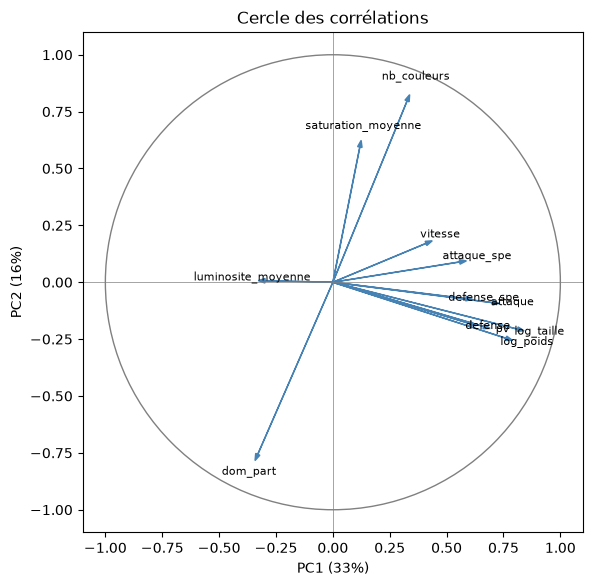

In [11]:
# le cercle des corrélations sur PC1 / PC2
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for v in VARIABLES_PCA:
    x, y = loadings.loc[v, "PC1"], loadings.loc[v, "PC2"]
    ax.arrow(0, 0, x, y, head_width=0.02, color="steelblue", length_includes_head=True)
    ax.text(x * 1.08, y * 1.08, v, fontsize=8, ha="center")
ax.axhline(0, color="grey", lw=.5); ax.axvline(0, color="grey", lw=.5)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.set_xlabel(f"PC1 ({variance.variance_expliquee.iloc[0]:.0%})")
ax.set_ylabel(f"PC2 ({variance.variance_expliquee.iloc[1]:.0%})")
ax.set_title("Cercle des corrélations")
plt.show()

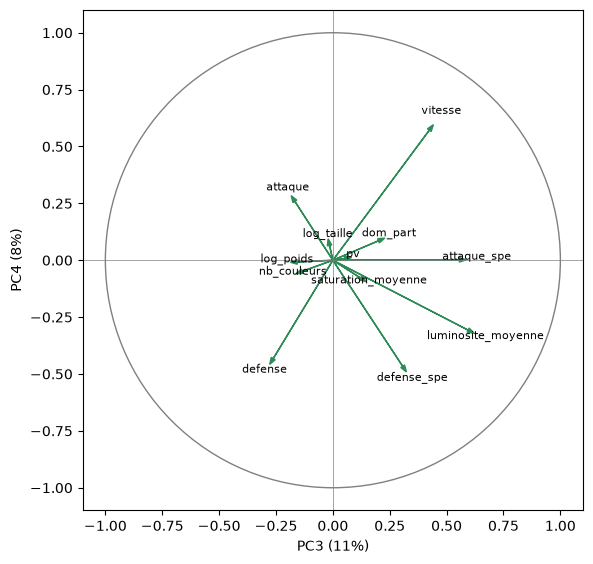

In [12]:
# un deuxième cercle pour PC3 / PC4
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for v in VARIABLES_PCA:
    x, y = loadings.loc[v, "PC3"], loadings.loc[v, "PC4"]
    ax.arrow(0, 0, x, y, head_width=0.02, color="seagreen", length_includes_head=True)
    ax.text(x * 1.08, y * 1.08, v, fontsize=8, ha="center")
ax.axhline(0, color="grey", lw=.5); ax.axvline(0, color="grey", lw=.5)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.set_xlabel(f"PC3 ({variance.variance_expliquee.iloc[2]:.0%})")
ax.set_ylabel(f"PC4 ({variance.variance_expliquee.iloc[3]:.0%})")
plt.show()

In [13]:
coords = pd.DataFrame(pca.transform(X)[:, :4], index=df.index, columns=["PC1", "PC2", "PC3", "PC4"])
coords = coords.join(df[["nom_fr", "generation", "stade_categorie", "legendaire", "fabuleux"]])
# les Pokémon aux extrémités de chaque axe
for pc in ["PC1", "PC2", "PC3"]:
    o = coords.sort_values(pc)
    print(f"{pc}  bas : {', '.join(o.nom_fr.head(6))}")
    print(f"{pc} haut : {', '.join(o.nom_fr.tail(6)[::-1])}")

PC1  bas : Froussardine, Frissonille, Azurill, Crèmy, Toudoudou, Bombydou
PC1 haut : Éthernatos, Giratina, Groudon, Arceus, Yveltal, Dialga
PC2  bas : Terraiste, Ama-Ama, Leveinard, Lamantine, Rhinocorne, Wagomine
PC2 haut : Yuyu, Théffroi, Crabagarre, Amphinobi, Crocogril, Cosmog
PC3  bas : Ama-Ama, Dolman, Galeking, Pomdepik, Gigalithe, Nodulithe
PC3 haut : Cancrelove, Zéroïd, Charmilly, Voltali, Regice, Corayôme


Les extrémités confirment la lecture : PC1 va des bébés et petits Pokémon (Crèmy, Azurill, Toudoudou) aux légendaires géants (Éthernatos, Groudon, Giratina, Arceus). PC2 va des Pokémon presque unis (Leveinard, Lamantine) aux designs chargés (Crocogril, Amphinobi, Théffroi). PC3 va des Pokémon de pierre ou d'acier (Nodulithe, Gigalithe, Galeking) aux Pokémon clairs et « spéciaux » (Charmilly, Regice, Voltali).

### Les Pokémon dans le plan factoriel, et la trajectoire des générations

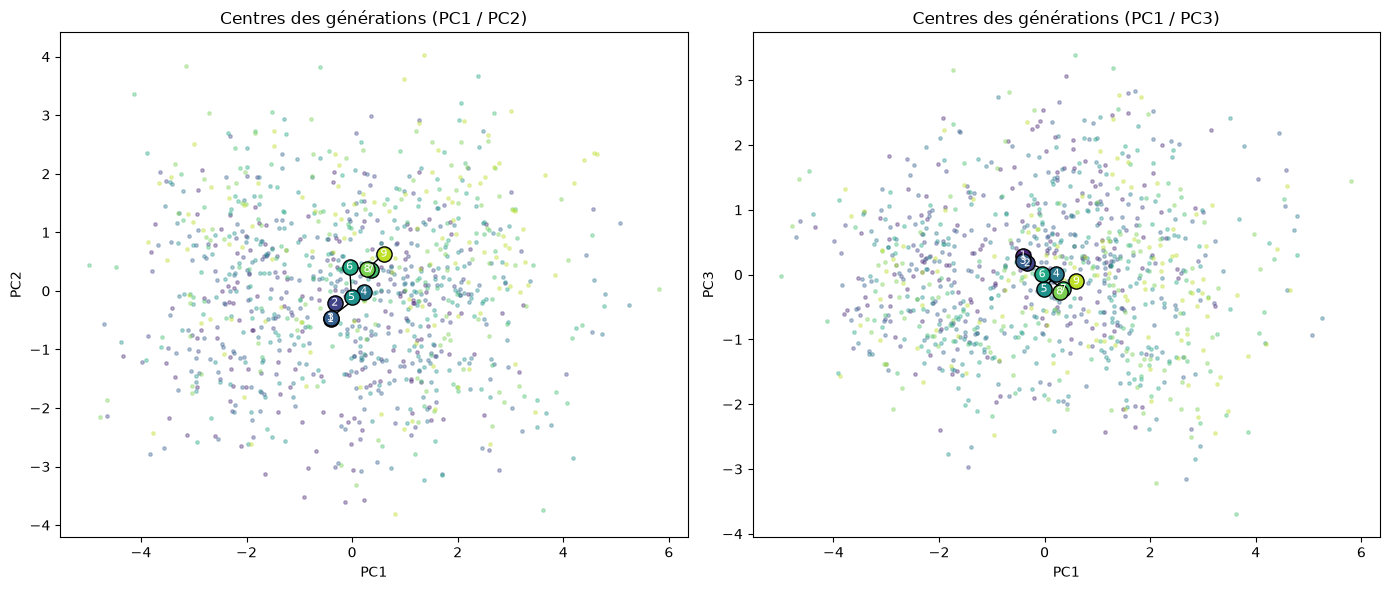

,PC1,PC2,PC3,PC4
generation,,,,
1,-0.41,-0.48,0.29,0.11
2,-0.33,-0.20,0.17,-0.25
3,-0.41,-0.46,0.21,-0.12
4,0.22,-0.01,0.01,0.01
5,-0.01,-0.11,-0.22,0.18
6,-0.05,0.41,0.00,-0.26
7,0.35,0.36,-0.22,-0.14
8,0.28,0.37,-0.26,0.17
9,0.60,0.63,-0.10,0.09


In [14]:
centres = coords.groupby("generation")[["PC1", "PC2", "PC3", "PC4"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
pal = sns.color_palette("viridis", 9)
for ax, (a, b) in zip(axes, [("PC1", "PC2"), ("PC1", "PC3")]):
    for g in range(1, 10):
        d = coords[coords.generation == g]
        ax.scatter(d[a], d[b], s=6, alpha=.35, color=pal[g - 1])
    ax.plot(centres[a], centres[b], "-", color="black", lw=1)
    for g in range(1, 10):
        ax.scatter(centres.loc[g, a], centres.loc[g, b], s=120, color=pal[g - 1], edgecolor="black", zorder=3)
        ax.text(centres.loc[g, a], centres.loc[g, b], str(g), ha="center", va="center", fontsize=8, color="white", zorder=4)
    ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f"Centres des générations ({a} / {b})")
plt.tight_layout()
plt.show()
centres.round(2)

Les centres des générations se déplacent **vers le haut à droite** : de (-0,41 ; -0,48) en génération 1 à (0,60 ; 0,63) en génération 9. Les générations 1 à 3 sont groupées ensemble, puis il y a un saut à la génération 4, et la génération 9 est la plus loin. Mais les écarts entre centres (environ une unité) sont petits par rapport à l'étalement des Pokémon dans chaque génération.

In [15]:
# même chose sans les légendaires et fabuleux, et à stade égal (stade 1, 2, 3 séparément)
masque = ~coords.legendaire & ~coords.fabuleux
traj = coords[masque].groupby(["stade_categorie", "generation"])[["PC1", "PC2"]].mean().round(2)
traj.unstack(0)

PC1                                    PC2          \
stade_categorie sans évolution stade 1 stade 2 stade 3 sans évolution stade 1   
generation                                                                      
1                         0.66   -1.84    0.17    1.01          -1.17   -0.15   
2                        -0.15   -1.91    0.36    1.29          -0.29   -0.03   
3                        -0.36   -2.28    0.04    1.63          -0.57   -0.38   
4                        -0.76   -1.94    0.79    1.95          -0.27    0.35   
5                         0.86   -1.94    0.54    1.74           0.09    0.07   
6                        -0.35   -2.04    0.71    1.65           0.20    0.29   
7                         0.92   -2.13    0.53    1.97          -0.17    0.86   
8                         1.12   -2.49    0.66    2.02           0.28    0.65   
9                         2.30   -2.36    0.77    2.09           0.89    0.58   

                                 
stade_categorie stade 2 stade 3  
generation                       
1                 -0.67   -0.50  
2                 -0.52   -0.11  
3                 -0.56   -0.20  
4                 -0.15   -0.06  
5                 -0.23   -0.15  
6                  0.45    1.12  
7                  0.25    1.04  
8                  0.36    0.13  
9                  0.40    0.60

À stade égal et sans légendaires, la montée sur PC2 (plus de couleurs) se voit surtout pour les stades 2 et 3 à partir de la génération 6 (sauf les stades 3 de la génération 8, qui retombent à 0,13). Sur PC1, les stades 3 sont plus « gros et forts » dans les générations récentes (1,01 en génération 1, autour de 2 à partir de la génération 7), alors que les stades 1 descendent un peu (de -1,84 à environ -2,4/-2,5 en générations 8 et 9).

In [16]:
# les tendances des axes avec la génération (Spearman), tous Pokémon puis ordinaires seulement
lignes = []
for nom, d in [("tous", coords), ("sans légendaires/fabuleux", coords[masque])]:
    for pc in ["PC1", "PC2", "PC3", "PC4"]:
        sp = stats.spearmanr(d["generation"], d[pc])
        lignes.append({"groupe": nom, "axe": pc, "rho": sp.statistic, "p": sp.pvalue})
pd.DataFrame(lignes).pivot(index="axe", columns="groupe", values=["rho", "p"]).round(4)

rho                                 p        
groupe sans légendaires/fabuleux    tous sans légendaires/fabuleux    tous
axe                                                                       
PC1                       0.1446  0.1647                    0.0000  0.0000
PC2                       0.2640  0.2584                    0.0000  0.0000
PC3                      -0.1588 -0.1615                    0.0000  0.0000
PC4                       0.0146  0.0356                    0.6557  0.2548

Les tendances avec la génération sont toutes significatives sauf PC4 : PC1 (0,14 à 0,16), PC2 (0,26) et PC3 (-0,16). Enlever les légendaires ne change presque rien, donc on peut les garder sans fausser la trajectoire. Le changement le plus net au fil du temps, c'est la couleur (PC2).

### Ce qu'on a fait et pourquoi

**1. Pourquoi une PCA.** On a 12 attributs de conception, et on veut voir comment les générations se déplacent « dans l'ensemble » sans faire 12 graphiques séparés. La PCA résume ces 12 variables en quelques axes qui regroupent les variables qui vont ensemble (par exemple taille, poids et stats qui montent ensemble = « gros et fort »).

**2. Standardiser avant.** La PCA cherche les directions où les données varient le plus. Sans standardiser, le total des stats (des centaines) écraserait la saturation (entre 0 et 1) juste à cause de l'unité. En mettant tout en moyenne 0 et écart-type 1, chaque variable part avec le même poids.

**3. Les choix de variables.** On a mis les 6 stats séparément pour que la PCA puisse voir des profils (rapide, défensif…), même si du coup les stats pèsent beaucoup sur le premier axe. On a laissé la teinte de côté parce que c'est un angle : 1° et 359° sont presque la même couleur, mais la PCA les verrait comme opposées.

**4. Combien d'axes garder : critère de Kaiser et éboulis.** On garde les axes qui ont une valeur propre au-dessus de 1, c'est-à-dire ceux qui résument plus d'information qu'une variable de départ toute seule (comme au TP4). L'éboulis (les barres de variance avec la courbe cumulée) permet de vérifier visuellement où ça « décroche ».

**5. Lire les axes : loadings et cercles des corrélations.** Un axe tout seul ne veut rien dire, il faut savoir quelles variables le portent. Les loadings donnent la corrélation entre chaque variable et chaque axe, et le cercle des corrélations le montre en dessin : une flèche longue près d'un axe = la variable compte beaucoup pour cet axe. On a fait un deuxième cercle pour PC3/PC4, parce que le premier ne montre que les deux premiers axes. On a aussi regardé les Pokémon aux deux bouts de chaque axe, pour vérifier que notre lecture (« gros et fort », « coloré »…) colle à de vrais Pokémon.

**6. La trajectoire des générations.** Plutôt que d'afficher 1 025 points illisibles, on a calculé le centre (la moyenne) de chaque génération dans le plan factoriel et on les a reliés dans l'ordre. Ça montre en un dessin dans quelle direction le design a bougé au fil du temps. On a laissé les Pokémon en fond, en transparent, pour qu'on voie que l'écart entre centres est petit par rapport à l'étalement dans chaque génération.

**7. Vérifier sans les légendaires.** Comme dans la partie 1, on a refait les tendances des axes sans légendaires et à stade égal, pour être sûrs que la trajectoire ne vient pas juste des légendaires.

## 3. Design ou nostalgie ?

Si les générations récentes sont moins aimées **à cause de leur design**, alors la position dans le plan factoriel devrait expliquer la popularité **à génération égale**. Du coup, pour cette partie, on décide d'utiliser les percentiles **dans la génération** (Reddit, Johto Times, Google Trends) : dans ces percentiles, l'effet génération (et donc la nostalgie) est retiré par construction, il ne reste que les différences entre Pokémon d'une même génération. Pour Google, on rappelle que les 28 Pokémon dont le nom est aussi un mot courant (Persian, Ditto, Golem…) ont été retirés dans le notebook 02 : ils n'ont pas de valeur Google, du coup les calculs Google se font seulement sur les Pokémon qui en ont une.

D'abord les corrélations de Spearman entre les axes et ces percentiles.

In [17]:
ys = {"reddit": "reddit_pct_gen", "johto": "johto_pct_gen", "trends": "trends_pct_gen"}
data = coords.join(df[list(ys.values()) + ["reddit_pct", "trends_pct_median"]])
lignes = []
for pc in ["PC1", "PC2", "PC3", "PC4"]:
    for s, y in ys.items():
        d = data[[pc, y]].dropna()
        sp = stats.spearmanr(d[pc], d[y])
        lignes.append({"axe": pc, "source": s, "rho": sp.statistic, "p": sp.pvalue, "n": len(d)})
corr_pop = pd.DataFrame(lignes)
corr_pop.pivot(index="axe", columns="source", values="rho").round(3)

source,johto,reddit,trends
axe,,,
PC1,0.371,0.363,0.174
PC2,0.003,-0.034,-0.017
PC3,0.222,0.158,0.108
PC4,0.032,0.054,0.099


À génération égale, **PC1 (« gros et fort ») est lié à la popularité** dans les trois sources (0,37 Johto, 0,36 Reddit, 0,17 Google). PC3 l'est aussi, plus faiblement (0,11 à 0,22). PC2, l'axe « coloré » qui change le plus avec les générations, **n'est lié à la popularité dans aucune source** (rho entre -0,03 et 0,00, p > 0,3).

In [18]:
corr_pop.pivot(index='axe', columns='source', values='p').round(4)

source,johto,reddit,trends
axe,,,
PC1,0.0000,0.0000,0.0000
PC2,0.9252,0.3405,0.5919
PC3,0.0000,0.0000,0.0006
PC4,0.3061,0.1265,0.0018


PC1 est très lié au stade d'évolution (les stades 3 sont gros et forts), et le stade est lui-même lié à la popularité (notebook 05). Pour voir si PC1 joue encore **à stade égal**, on refait les corrélations à l'intérieur de chaque catégorie de stade.

In [19]:
lignes = []
for st, d in data.join(df["stade_categorie"].rename("stade")).groupby("stade"):
    for pc in ["PC1", "PC2", "PC3"]:
        for s, y in ys.items():
            dd = d[[pc, y]].dropna()
            sp = stats.spearmanr(dd[pc], dd[y])
            lignes.append({"stade": st, "axe": pc, "source": s, "rho": round(sp.statistic, 3), "p": round(sp.pvalue, 4), "n": len(dd)})
par_stade = pd.DataFrame(lignes)
par_stade.pivot(index=["axe", "stade"], columns="source", values="rho")

source              johto  reddit  trends
axe stade                                
PC1 sans évolution  0.164   0.000   0.296
    stade 1        -0.001   0.115  -0.026
    stade 2         0.377   0.394   0.286
    stade 3         0.264   0.291   0.409
PC2 sans évolution -0.030  -0.125  -0.007
    stade 1         0.041   0.021   0.053
    stade 2         0.003  -0.010  -0.142
    stade 3         0.047  -0.029  -0.056
PC3 sans évolution  0.314   0.045   0.264
    stade 1         0.187   0.097   0.043
    stade 2         0.138   0.122   0.019
    stade 3         0.083   0.102   0.076

In [20]:
par_stade.pivot(index=['axe', 'stade'], columns='source', values='p')

source               johto  reddit  trends
axe stade                                 
PC1 sans évolution  0.0202  0.9990  0.0000
    stade 1         0.9807  0.0528  0.6342
    stade 2         0.0000  0.0000  0.0000
    stade 3         0.0034  0.0037  0.0000
PC2 sans évolution  0.6766  0.1433  0.9243
    stade 1         0.4509  0.7221  0.3369
    stade 2         0.9516  0.8709  0.0071
    stade 3         0.6105  0.7747  0.5420
PC3 sans évolution  0.0000  0.5995  0.0002
    stade 1         0.0005  0.1028  0.4333
    stade 2         0.0086  0.0384  0.7179
    stade 3         0.3662  0.3190  0.4067

À stade égal, le lien de PC1 avec la popularité **reste fort pour les stades 2 et 3** (0,26 à 0,41, p < 0,01 partout), mais **disparaît presque pour les stades 1** (0,00 au Johto Times, -0,03 sur Google, 0,12 sur Reddit avec p = 0,053, juste au-dessus du seuil de 5 %). En gros : parmi les formes évoluées, les plus grosses et fortes sont plus aimées ; chez les premiers stades, ça ne joue pas. PC2 (la couleur) ne ressort toujours dans aucun stade (une seule p < 0,05 sur 12, sur Google pour les stades 2, avec un rho négatif de -0,14).

Ensuite, une **régression** popularité ~ génération + axes. Ici il faut un percentile **global** (sinon on ne peut pas mesurer l'effet génération), donc on la fait seulement pour Reddit et Google Trends : le Johto Times n'existe qu'en percentile dans la génération. L'idée : si l'effet génération baisse beaucoup quand on ajoute les axes, c'est que le design « explique » une partie de l'écart entre générations. S'il reste à peu près pareil, l'écart entre générations ne passe pas par ces attributs de conception.

In [21]:
lignes = []
coefs_gen = {}
for s, y in [("reddit", "reddit_pct"), ("trends", "trends_pct_median")]:
    d = data.dropna(subset=[y])
    m0 = smf.ols(f"{y} ~ C(generation)", data=d).fit(cov_type="HC3")
    m1 = smf.ols(f"{y} ~ C(generation) + PC1 + PC2 + PC3 + PC4", data=d).fit(cov_type="HC3")
    lignes.append({"source": s, "R2_gen_seule": m0.rsquared_adj, "R2_gen_plus_axes": m1.rsquared_adj})
    coefs_gen[(s, "génération seule")] = m0.params.filter(like="generation")
    coefs_gen[(s, "génération + axes")] = m1.params.filter(like="generation")
    print(f"=== {s} : coefficients des axes (modèle avec génération)")
    print(pd.DataFrame({"coef": m1.params[["PC1", "PC2", "PC3", "PC4"]], "p": m1.pvalues[["PC1", "PC2", "PC3", "PC4"]]}).round(4).to_string())
r2 = pd.DataFrame(lignes).set_index("source")
display(r2.round(3))
pd.DataFrame(coefs_gen).round(3)

=== reddit : coefficients des axes (modèle avec génération)
       coef       p
PC1  0.0481  0.0000
PC2  0.0016  0.8100
PC3  0.0324  0.0000
PC4  0.0153  0.0903
=== trends : coefficients des axes (modèle avec génération)
       coef       p
PC1  0.0236  0.0000
PC2 -0.0009  0.8887
PC3  0.0257  0.0002
PC4  0.0267  0.0004


,R2_gen_seule,R2_gen_plus_axes
source,,
reddit,0.174,0.294
trends,0.183,0.228


reddit                             trends  \
                   génération seule génération + axes génération seule   
C(generation)[T.2]           -0.044            -0.039           -0.160   
C(generation)[T.3]           -0.155            -0.149           -0.218   
C(generation)[T.4]           -0.131            -0.151           -0.182   
C(generation)[T.5]           -0.302            -0.306           -0.349   
C(generation)[T.6]           -0.262            -0.266           -0.230   
C(generation)[T.7]           -0.344            -0.361           -0.282   
C(generation)[T.8]              NaN               NaN           -0.347   
C(generation)[T.9]              NaN               NaN           -0.402   

                                      
                   génération + axes  
C(generation)[T.2]            -0.149  
C(generation)[T.3]            -0.210  
C(generation)[T.4]            -0.186  
C(generation)[T.5]            -0.348  
C(generation)[T.6]            -0.220  
C(generation)[T.7]            -0.279  
C(generation)[T.8]            -0.350  
C(generation)[T.9]            -0.413

Avec la génération seule, le modèle explique 17 % de la popularité pour Reddit et 18 % pour Google ; ajouter les 4 axes monte à 29 % (Reddit) et 23 % (Google). Les axes apportent donc de l'information **en plus** de la génération (surtout PC1 et PC3).

Par contre, **les coefficients des générations ne bougent presque pas** quand on ajoute les axes : par exemple génération 7 sur Reddit, -0,34 sans les axes et -0,36 avec ; génération 9 sur Google, -0,40 et -0,41. Autrement dit, l'écart de popularité entre générations **ne passe pas par ces attributs de conception** (taille, stats, couleurs) : à design égal, les générations récentes restent aussi moins aimées. Ça ne prouve pas que c'est la nostalgie (il y a d'autres différences entre générations qu'on ne mesure pas ici : le style de dessin, l'anime…), mais les attributs mesurés ici n'expliquent pas cet écart.

### Ce qu'on a fait et pourquoi

**1. Les percentiles dans la génération.** La question, c'est « design ou nostalgie ? ». Si on comparait la popularité globale, l'effet génération (et donc peut-être la nostalgie) serait mélangé avec le design. Dans les percentiles **dans la génération**, chaque Pokémon n'est comparé qu'aux Pokémon de sa génération : l'effet génération est retiré par construction, et s'il reste un lien avec les axes, c'est le design qui joue.

**2. Spearman entre axes et popularité.** On travaille avec des percentiles, donc des rangs : Spearman est naturel, et il ne suppose pas que le lien est une ligne droite. On garde les trois sources à part, comme dans tout le projet.

**3. Refaire les corrélations à stade égal.** Le premier axe (« gros et fort ») est très lié au stade d'évolution, et le stade est lui-même lié à la popularité (notebook 05). Sans couper par stade, on pourrait croire que c'est la taille qui plaît alors que c'est juste « les formes finales plaisent ». En regardant à l'intérieur de chaque stade, on enlève ce piège.

**4. La régression avec et sans les axes.** C'est le test central de la partie. On compare deux modèles : popularité ~ génération, puis popularité ~ génération + axes. Si l'effet des générations baissait beaucoup en ajoutant les axes, ça voudrait dire que l'écart entre générations passe par le design. S'il ne bouge pas, le design n'explique pas cet écart. Ici il faut un percentile **global** (sinon il n'y a pas d'effet génération à mesurer), donc on ne peut le faire qu'avec Reddit et Google, pas avec le Johto Times.

**5. Les détails de la régression.** On met la génération en **catégories** (`C(generation)`) et pas en nombre, parce que rien ne dit que la popularité baisse régulièrement d'une génération à l'autre. On utilise des **erreurs robustes (HC3)**, parce qu'avec des percentiles la variance n'est sûrement pas la même partout, et les erreurs classiques seraient trop optimistes. On compare les **R² ajustés**, qui pénalisent le fait d'ajouter des variables : sinon ajouter 4 axes ferait forcément monter le R².

**6. Ce que ça ne prouve pas.** Si les attributs mesurés n'expliquent pas l'écart entre générations, ça ne prouve pas que c'est la nostalgie : il peut y avoir d'autres différences qu'on ne mesure pas (style de dessin, anime…). On l'écrit pour ne pas conclure trop vite.

## 4. Export

In [22]:
coords[["PC1", "PC2", "PC3", "PC4"]].to_csv(OUT / "pca_conception.csv")
coords.shape

(1025, 9)

On exporte aussi les résultats intermédiaires pour pouvoir montrer la méthode dans le dashboard : les valeurs propres, les loadings, les corrélations de Spearman avec la popularité, les coefficients des générations dans la régression et les R² ajustés.

In [23]:
# petits fichiers pour la page Méthodes du dashboard
noms_lisibles = {"pv": "PV", "attaque": "Attaque", "defense": "Défense", "attaque_spe": "Attaque spé.",
                 "defense_spe": "Défense spé.", "vitesse": "Vitesse", "log_taille": "taille (log)",
                 "log_poids": "poids (log)", "nb_couleurs": "nb de couleurs", "saturation_moyenne": "saturation",
                 "luminosite_moyenne": "luminosité", "dom_part": "part couleur dominante"}

# valeurs propres et part de variance des 12 composantes
pd.DataFrame({"composante": range(1, len(VARIABLES_PCA) + 1),
              "valeur_propre": pca.explained_variance_,
              "part_variance": pca.explained_variance_ratio_}).to_csv(OUT / "methode_06_acp.csv", index=False)

# loadings (corrélation variable <-> axe) des 4 axes gardés
loadings.rename(index=noms_lisibles).rename_axis("variable").reset_index().to_csv(
    OUT / "methode_06_loadings.csv", index=False)

# Spearman axes <-> percentiles dans la génération
corr_pop.rename(columns={"p": "p_valeur"})[["axe", "source", "rho", "p_valeur"]].to_csv(
    OUT / "methode_06_spearman.csv", index=False)

# coefficients des générations, sans et avec les axes (Reddit n'a pas les générations 8 et 9)
lignes_reg = []
for s in ["reddit", "trends"]:
    sans, avec = coefs_gen[(s, "génération seule")], coefs_gen[(s, "génération + axes")]
    for terme in sans.index:
        lignes_reg.append({"source": s, "generation": int(terme.split("T.")[1].rstrip("]")),
                           "coef_sans_axes": sans[terme], "coef_avec_axes": avec[terme]})
pd.DataFrame(lignes_reg).to_csv(OUT / "methode_06_regression.csv", index=False)

# R² ajustés des deux modèles
pd.concat([pd.DataFrame({"source": r2.index, "modele": "génération seule", "r2_ajuste": r2["R2_gen_seule"].values}),
           pd.DataFrame({"source": r2.index, "modele": "génération + axes", "r2_ajuste": r2["R2_gen_plus_axes"].values})]
          ).to_csv(OUT / "methode_06_r2.csv", index=False)
